<a href="https://colab.research.google.com/github/Ayushi-Sharma19/DIP/blob/main/filters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mean Filter

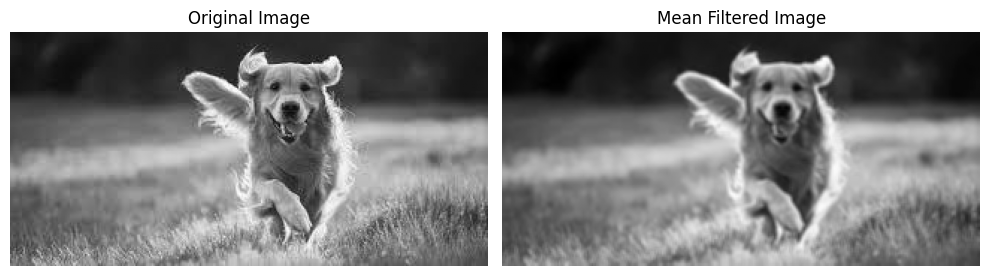

In [1]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Apply mean filter
mean = cv2.blur(img, (3, 3))

# Display images side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mean, cmap='gray')
plt.title('Mean Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

Weighted Average Filter


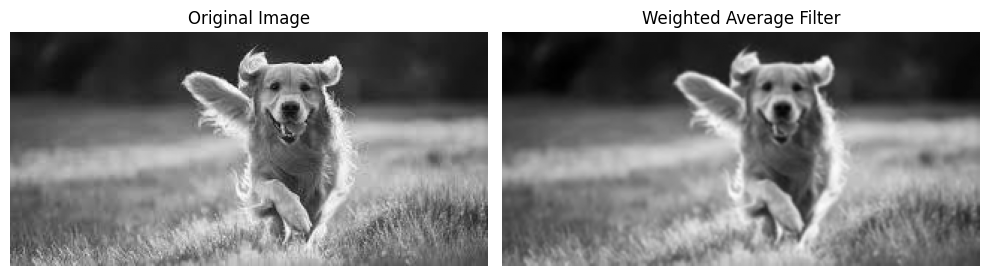

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Define weighted average kernel
kernel = np.array([[1, 2, 1],
                   [2, 4, 2],
                   [1, 2, 1]], dtype=np.float32) / 16

# Apply weighted average filter
filtered = cv2.filter2D(img, -1, kernel)

# Display images side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered, cmap='gray')
plt.title('Weighted Average Filter')
plt.axis('off')

plt.tight_layout()
plt.show()

Gaussian smoothing

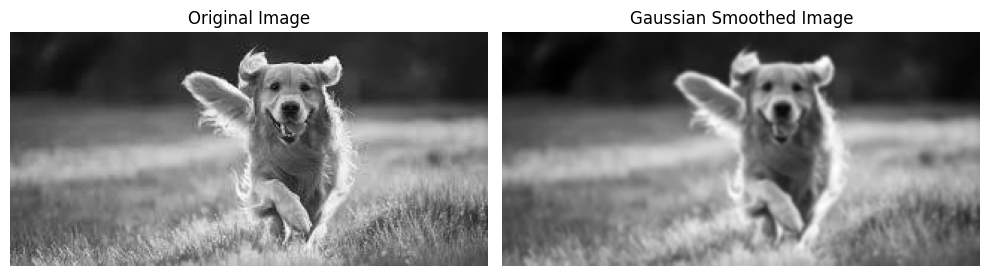

In [3]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Apply Gaussian filter
gaussian = cv2.GaussianBlur(img, (5, 5), 1)

# Display images side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gaussian, cmap='gray')
plt.title('Gaussian Smoothed Image')
plt.axis('off')

plt.tight_layout()
plt.show()

Median Filter

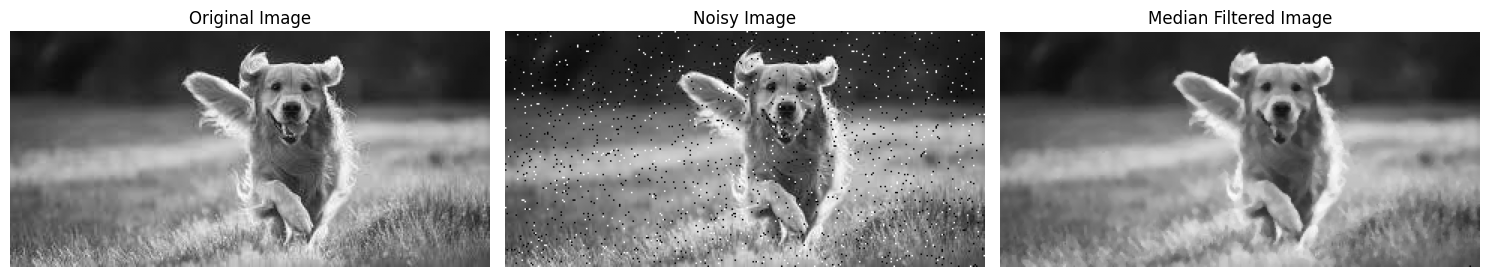

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Add salt and pepper noise
noisy = img.copy()
noise = np.random.randint(0, 100, img.shape)

noisy[noise < 2] = 0
noisy[noise > 98] = 255

# Apply median filter
median = cv2.medianBlur(noisy, 3)

# Display images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(noisy, cmap='gray')
plt.title('Noisy Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(median, cmap='gray')
plt.title('Median Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

Laplacian sharpening


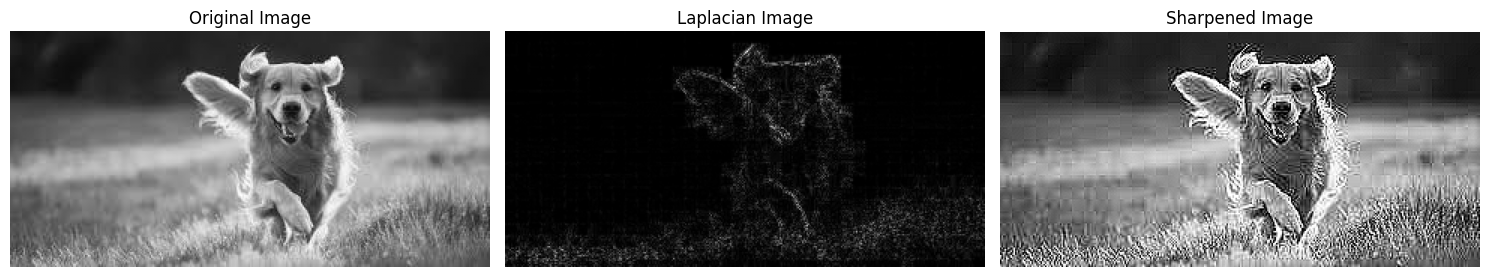

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Apply Laplacian operator
laplacian = cv2.Laplacian(img, cv2.CV_64F)

# Sharpen image using Laplacian
sharpened = np.clip(
    img.astype(np.float64) - laplacian,
    0, 255
).astype(np.uint8)

# Display images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.abs(laplacian), cmap='gray')
plt.title('Laplacian Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sharpened, cmap='gray')
plt.title('Sharpened Image')
plt.axis('off')

plt.tight_layout()
plt.show()

Sobel edge detection

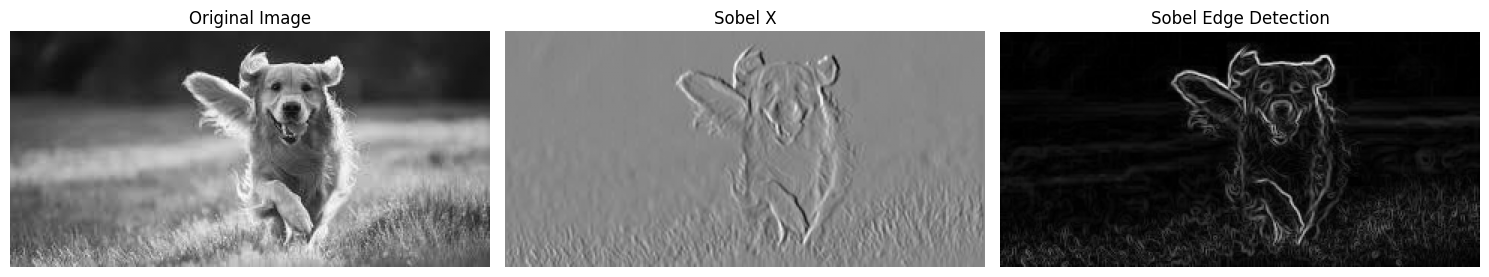

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Apply Sobel operator
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

# Calculate gradient magnitude
sobel = np.sqrt(sobel_x**2 + sobel_y**2)

# Normalize result
sobel = cv2.normalize(
    sobel, None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Display images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(sobel_x, cmap='gray')
plt.title('Sobel X')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sobel, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')

plt.tight_layout()
plt.show()

High-boost filtering

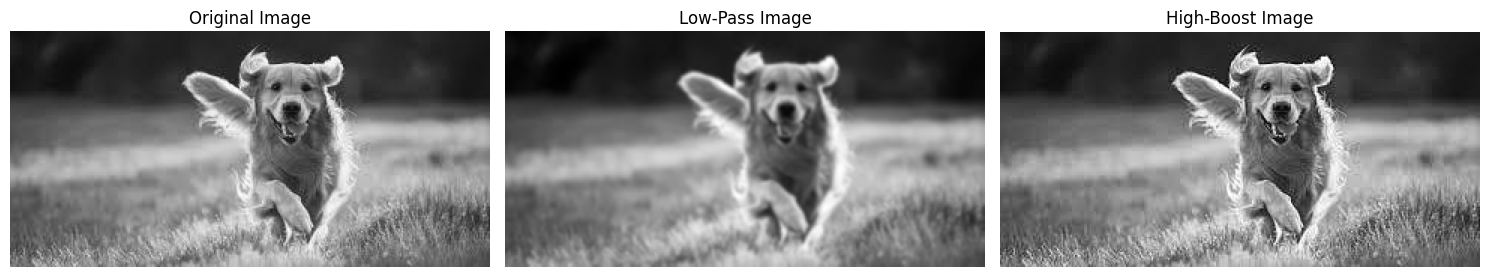

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Apply low-pass filter
blur = cv2.GaussianBlur(img, (5, 5), 1)

# Set amplification factor
A = 1.5

# Apply high-boost filtering
high_boost = cv2.addWeighted(img, A, blur, 1-A, 0)

# Display images side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blur, cmap='gray')
plt.title('Low-Pass Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(high_boost, cmap='gray')
plt.title('High-Boost Image')
plt.axis('off')

plt.tight_layout()
plt.show()

Frequency-domain filters

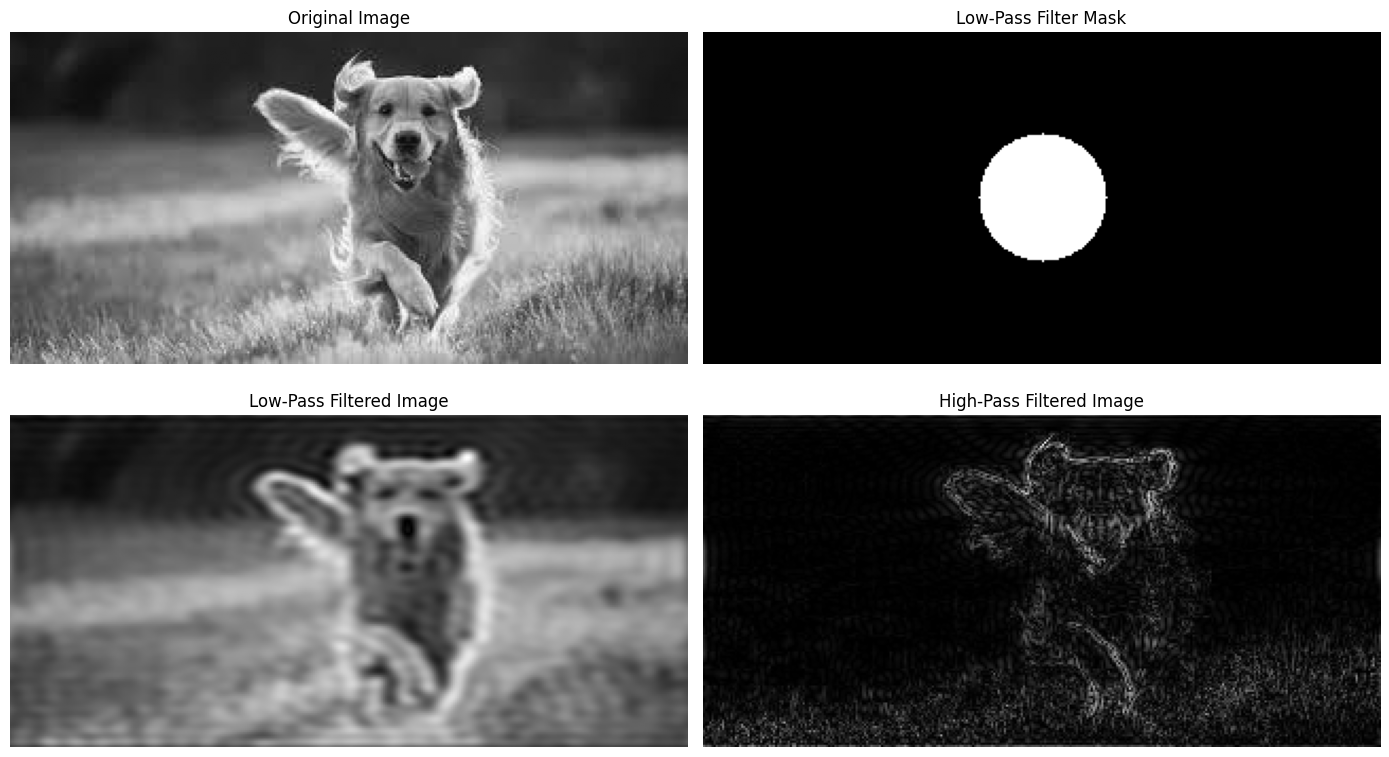

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('image.jpg', 0)

# Apply Fourier Transform
dft = np.fft.fft2(img)
dft_shift = np.fft.fftshift(dft)

# Get image dimensions
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

# Create low-pass filter mask
mask = np.zeros((rows, cols), np.uint8)
radius = 30

cv2.circle(mask, (ccol, crow), radius, 1, -1)

# Apply low-pass filter
low_pass = dft_shift * mask

# Create high-pass filter mask
high_mask = 1 - mask

# Apply high-pass filter
high_pass = dft_shift * high_mask

# Inverse Fourier Transform
low_img = np.fft.ifft2(np.fft.ifftshift(low_pass))
high_img = np.fft.ifft2(np.fft.ifftshift(high_pass))

# Get absolute values
low_img = np.abs(low_img)
high_img = np.abs(high_img)

# Normalize results for display
low_img = cv2.normalize(
    low_img, None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

high_img = cv2.normalize(
    high_img, None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Display results
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(mask, cmap='gray')
plt.title('Low-Pass Filter Mask')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(low_img, cmap='gray')
plt.title('Low-Pass Filtered Image')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(high_img, cmap='gray')
plt.title('High-Pass Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()